# 08. Non-AI Rule-Based Fall Detection Baseline

## Executive Overview

Before deploying complex Deep Learning architectures (**ResNet-18** on Micro-Doppler maps / 2D Spatial Projections, or **PointNet++** on 3D Point Clouds), establishing a **rigorous, transparent, non-AI baseline** is essential. This notebook implements physical heuristic rules based on raw mmWave radar point cloud characteristics to detect falls without neural network training.

### Physical Heuristics for Non-AI Fall Detection
1. **Vertical Posture Drop ($\Delta z$ / `drop_z`)**: Measures rapid downward elevation reduction from upright standing/walking ($z \approx 1.2 - 1.8\text{m}$) to near floor level ($z < 0.5\text{m}$).
2. **Peak Doppler Radial Velocity ($|v|_{\max}$)**: Captures sudden downward kinetic acceleration during fall descent ($|v| > 1.0 - 2.5\text{m/s}$).
3. **Post-Motion Settlement Height ($z_{\text{final}}$)**: Evaluates whether the person remains prone near the floor level after motion ceases.
4. **Spatial Ground Dispersion ($\text{Span}_{xy}$)**: Measures ground plane expansion as the torso hits the floor.
5. **Physics Composite Index Score ($S$)**: Weighted physical score combining drop, speed, and floor height.

### Zero-Leakage Evaluation Protocol
- **Dataset**: TI IWR6843 mmWave Radar Fall Detection Dataset (**102 CSV files**: 51 Falls vs 51 ADLs / Non-Falls).
- **Subjects**: `Areeb` (34 files), `Raffay` (34 files), `Towsif` (34 files).
- **Evaluation Protocol**: **3-Fold Leave-One-Subject-Out (LOSO) Cross-Validation**. Threshold parameters are calibrated strictly on training subjects and evaluated on the held-out subject.

In [9]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
try:
    from IPython.display import display
except ImportError:
    display = print

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.rule_baseline import extract_dataset_rule_features, RuleBasedFallDetector, evaluate_loso_rule_baseline
from src.dataset_parser import get_loso_splits

# Set Matplotlib aesthetic style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Feature Extraction Across All 102 CSV Recordings

We extract physical features across sliding temporal windows (10 frames = 1.0s) for all 102 CSV recording files.

In [10]:
df_features = extract_dataset_rule_features()
print(f"Extracted physical features for {len(df_features)} recording files.")
df_features.head(10)

Extracted physical features for 102 recording files.


,file,path,subject,label,drop_z,delta_z,max_abs_v,min_v,final_z,xy_span,max_z,num_windows
0,Areeb_back_1.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.062224,2.333832,0.2786,-0.2786,-0.118422,5.047241,1.836553,3
1,Areeb_back_2.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.045492,2.120050,0.2786,-0.2786,-0.054136,4.674361,1.643574,3
2,Areeb_back_3.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.108650,2.165669,0.2985,-0.2985,-0.123194,4.703012,1.667196,3
3,Areeb_back_4.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.019646,2.210648,0.2985,-0.2786,-0.106175,4.475486,1.761367,4
4,Areeb_back_5.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.021640,2.349801,0.2985,-0.2985,-0.030244,4.338880,1.857637,4
5,Areeb_front_1.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.019361,2.202556,0.3184,-0.3184,-0.012725,4.415784,1.843612,3
6,Areeb_front_2.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.361034,2.225343,0.2985,-0.2786,-0.106688,4.748954,1.752652,3
7,Areeb_front_3.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.006342,1.366760,0.2985,-0.2985,-0.008704,4.815789,0.909820,4
8,Areeb_front_4.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.192083,1.998403,0.2985,-0.2786,-0.108945,4.744825,1.594091,3
9,Areeb_front_5.csv,C:\Users\joeyw\GitProjects\klas-1-team-2\mmWav...,Areeb,1,0.008016,2.073797,0.3184,-0.3184,-0.058449,5.181527,1.669515,3


### Feature Summary Statistics by Class (Fall vs. Non-Fall ADL)

In [11]:
summary_by_class = df_features.groupby("label")[["drop_z", "delta_z", "max_abs_v", "final_z", "xy_span"]].agg(['mean', 'std', 'median', 'min', 'max'])
display(summary_by_class)

drop_z                                          delta_z            \
           mean       std   median       min       max      mean       std   
label                                                                        
0      0.079579  0.082641  0.06526 -0.086554  0.397206  1.901347  0.588130   
1      0.110219  0.102928  0.06514 -0.007714  0.376299  1.686121  0.665873   

                                     ...   final_z                      \
         median       min       max  ...      mean       std    median   
label                                ...                                 
0      2.059143  0.649871  2.672460  ... -0.039944  0.060126 -0.028858   
1      1.980730  0.421420  2.641013  ... -0.081155  0.105600 -0.085350   

                            xy_span                                          
            min       max      mean       std    median       min       max  
label                                                                        
0     -0.276880  0.059524  4.274486  0.693278  4.136419  2.998037  7.005521  
1     -0.301199  0.068561  4.445472  0.583082  4.624777  3.490001  5.432758  

[2 rows x 25 columns]

## 2. Visualizing Physical Feature Distributions (Fall vs. ADL)

We compare feature distributions between Fall events ($y=1$) and Non-Fall ADLs ($y=0$).

C:\Users\joeyw\AppData\Local\Temp\ipykernel_29064\1291629843.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='Class', y='drop_z', ax=axes[0, 0], palette=['#337ab7', '#d9534f'])
C:\Users\joeyw\AppData\Local\Temp\ipykernel_29064\1291629843.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='Class', y='max_abs_v', ax=axes[0, 1], palette=['#337ab7', '#d9534f'])
C:\Users\joeyw\AppData\Local\Temp\ipykernel_29064\1291629843.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot, x='Class', y='final_z

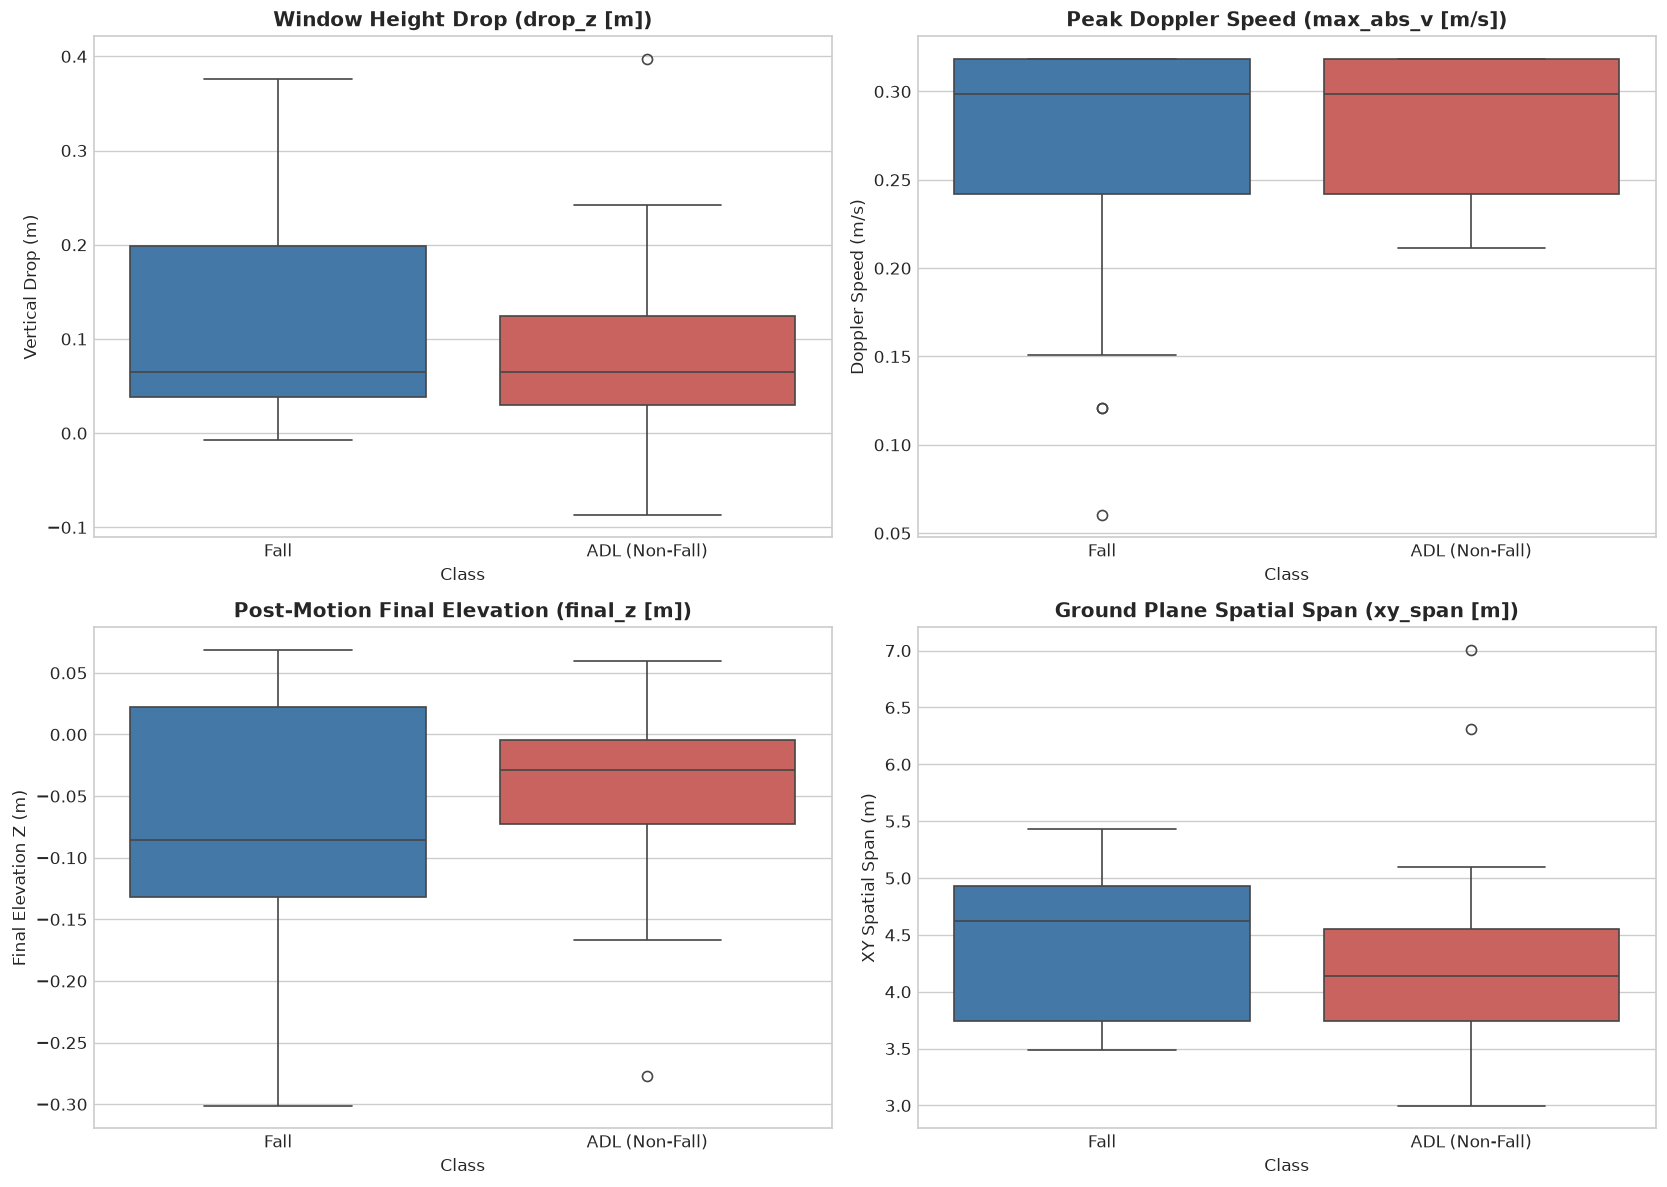

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

labels_map = {0: 'ADL (Non-Fall)', 1: 'Fall'}
df_plot = df_features.copy()
df_plot['Class'] = df_plot['label'].map(labels_map)

# Plot 1: Window Height Drop (drop_z)
sns.boxplot(data=df_plot, x='Class', y='drop_z', ax=axes[0, 0], palette=['#337ab7', '#d9534f'])
axes[0, 0].set_title('Window Height Drop (drop_z [m])', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Vertical Drop (m)')

# Plot 2: Max Doppler Speed (max_abs_v)
sns.boxplot(data=df_plot, x='Class', y='max_abs_v', ax=axes[0, 1], palette=['#337ab7', '#d9534f'])
axes[0, 1].set_title('Peak Doppler Speed (max_abs_v [m/s])', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Doppler Speed (m/s)')

# Plot 3: Post-Motion Settlement Height (final_z)
sns.boxplot(data=df_plot, x='Class', y='final_z', ax=axes[1, 0], palette=['#337ab7', '#d9534f'])
axes[1, 0].set_title('Post-Motion Final Elevation (final_z [m])', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Final Elevation Z (m)')

# Plot 4: Ground Plane Spatial Dispersion (xy_span)
sns.boxplot(data=df_plot, x='Class', y='xy_span', ax=axes[1, 1], palette=['#337ab7', '#d9534f'])
axes[1, 1].set_title('Ground Plane Spatial Span (xy_span [m])', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('XY Spatial Span (m)')

plt.tight_layout()
plt.show()

## 3. 3-Fold Leave-One-Subject-Out (LOSO) Cross-Validation

We evaluate 5 distinct non-AI rule strategies across the 3 LOSO folds (`Areeb`, `Raffay`, `Towsif`):
1. **Rule 1: Window Height Drop** (`drop_z >= thr`)
2. **Rule 2: Max Radial Doppler Speed** (`max_abs_v >= thr`)
3. **Rule 3: Dual Physical Heuristic** (`drop_z >= thr_z AND max_abs_v >= thr_v`)
4. **Rule 4: Multi-Criteria Rule** (`drop_z >= thr_z AND max_abs_v >= thr_v AND final_z <= thr_fz`)
5. **Rule 5: Composite Physics Index Score** (`drop_z + w_v * max_abs_v - w_fz * final_z >= thr`)

In [13]:
rule_strategies = [
    ("Rule 1: Height Drop", "drop_z"),
    ("Rule 2: Max Doppler Velocity", "max_abs_v"),
    ("Rule 3: Dual Heuristic (Drop + Speed)", "dual"),
    ("Rule 4: Multi-Criteria Physics", "multi"),
    ("Rule 5: Composite Physics Index Score", "composite")
]

results_list = []
results_dict = {}

for label_name, rule_key in rule_strategies:
    eval_res = evaluate_loso_rule_baseline(df_features, rule_type=rule_key)
    results_dict[rule_key] = eval_res
    results_list.append({
        "Rule Strategy": label_name,
        "Accuracy (%)": round(eval_res["accuracy"] * 100, 2),
        "Precision (%)": round(eval_res["precision"] * 100, 2),
        "Recall (%)": round(eval_res["recall"] * 100, 2),
        "Macro F1 (%)": round(eval_res["macro_f1"] * 100, 2),
        "ROC-AUC": round(eval_res["roc_auc"], 4),
        "False Alarm Rate / FPR (%)": round(eval_res["fpr"] * 100, 2)
    })

df_loso_summary = pd.DataFrame(results_list)
display(df_loso_summary)

,Rule Strategy,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),ROC-AUC,False Alarm Rate / FPR (%)
0,Rule 1: Height Drop,51.96,51.67,60.78,55.86,0.5613,56.86
1,Rule 2: Max Doppler Velocity,43.14,46.15,82.35,59.15,0.4514,96.08
2,Rule 3: Dual Heuristic (Drop + Speed),49.02,49.12,54.90,51.85,0.5190,56.86
3,Rule 4: Multi-Criteria Physics,49.02,49.12,54.90,51.85,0.5390,56.86
4,Rule 5: Composite Physics Index Score,50.00,50.00,90.20,64.34,0.5602,90.20


### Per-Fold Breakdown for Rule Strategies

In [14]:
fold_rows = []
for rule_key, eval_res in results_dict.items():
    for fold_info in eval_res["fold_details"]:
        fold_rows.append({
            "Rule Key": rule_key,
            "Fold": fold_info["fold"],
            "Test Subject": fold_info["test_subject"],
            "Accuracy (%)": round(fold_info["accuracy"] * 100, 2),
            "Macro F1 (%)": round(fold_info["macro_f1"] * 100, 2),
            "Calibrated Parameters": str(fold_info["calibrated_params"])
        })
df_folds = pd.DataFrame(fold_rows)
display(df_folds)

,Rule Key,Fold,Test Subject,Accuracy (%),Macro F1 (%),Calibrated Parameters
0,drop_z,0,Areeb,44.12,48.65,{'thr': 0.05}
1,drop_z,1,Raffay,47.06,43.75,{'thr': 0.05}
2,drop_z,2,Towsif,64.71,71.43,{'thr': 0.05}
3,max_abs_v,0,Areeb,50.00,66.67,{'thr': 0.1}
4,max_abs_v,1,Raffay,29.41,40.00,{'thr': 0.24000000000000002}
5,max_abs_v,2,Towsif,50.00,66.67,{'thr': 0.1}
6,dual,0,Areeb,44.12,48.65,"{'thr_z': 0.05, 'thr_v': 0.2}"
7,dual,1,Raffay,38.24,27.59,"{'thr_z': 0.05, 'thr_v': 0.2}"
8,dual,2,Towsif,64.71,71.43,"{'thr_z': 0.05, 'thr_v': 0.2}"
9,multi,0,Areeb,44.12,48.65,"{'thr_z': 0.05, 'thr_v': 0.2, 'thr_fz': 0.1}"


## 4. Visualizing ROC Curves and Confusion Matrices

We plot the Out-of-Fold (OOF) ROC curves and confusion matrix for the non-AI baseline.

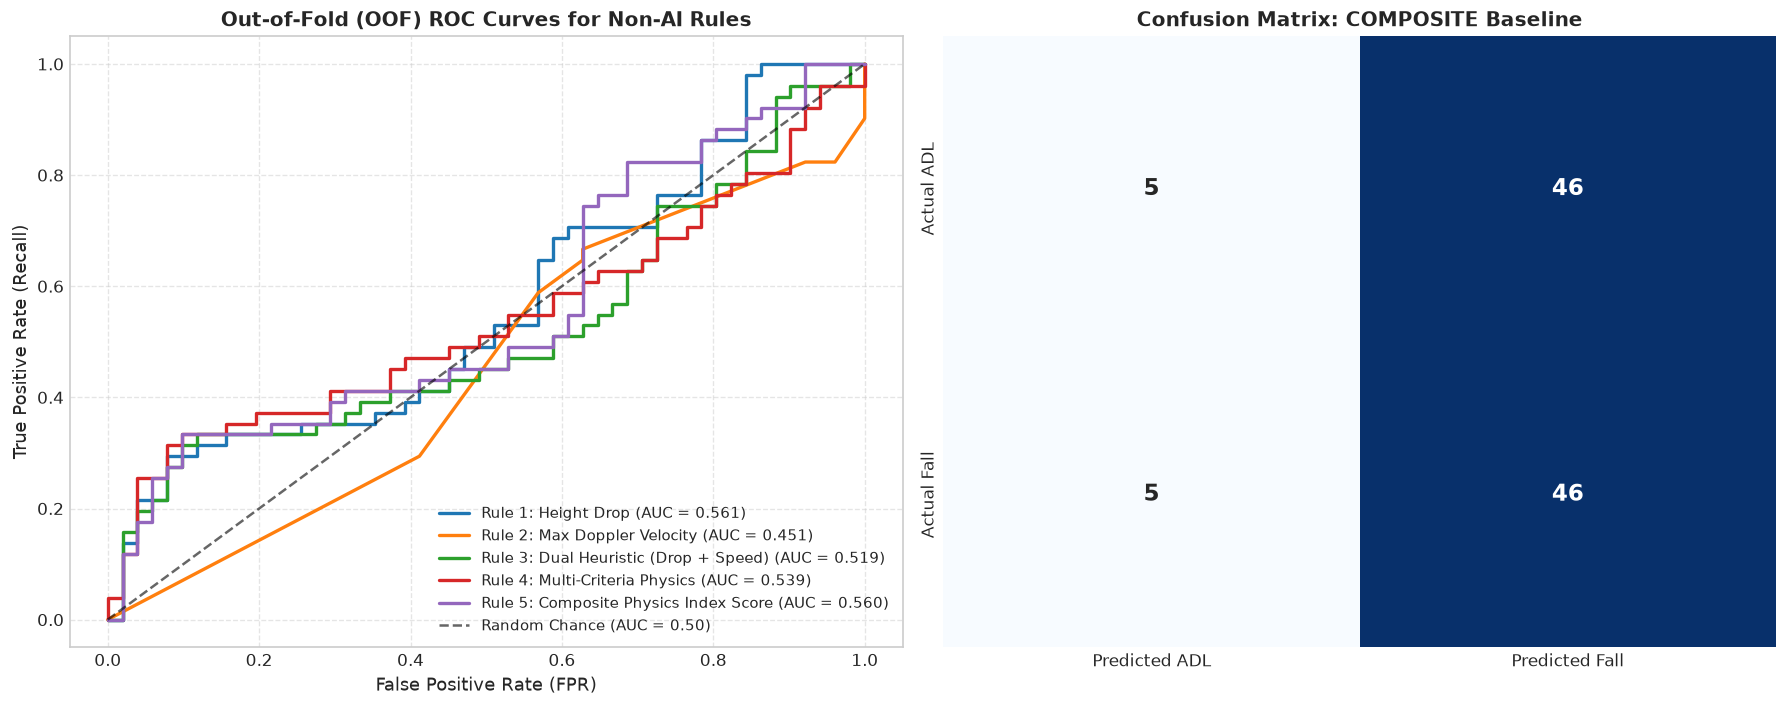

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC Curves
for label_name, rule_key in rule_strategies:
    res = results_dict[rule_key]
    fpr, tpr, _ = roc_curve(res["oof_y_true"], res["oof_y_score"])
    axes[0].plot(fpr, tpr, label=f"{label_name} (AUC = {res['roc_auc']:.3f})", linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Chance (AUC = 0.50)')
axes[0].set_xlabel('False Positive Rate (FPR)', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0].set_title('Out-of-Fold (OOF) ROC Curves for Non-AI Rules', fontsize=12, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Confusion Matrix for Best Rule Baseline (Composite Score / Height Drop)
best_rule_key = "composite"
cm = np.array(results_dict[best_rule_key]["confusion_matrix"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Predicted ADL', 'Predicted Fall'],
            yticklabels=['Actual ADL', 'Actual Fall'], cbar=False,
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title(f'Confusion Matrix: {best_rule_key.upper()} Baseline', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Comparative Benchmark: Non-AI Baseline vs. Deep Learning Models

We compare our Non-AI Rule-Based Baseline against deep learning architectures evaluated on the same 3-Fold LOSO benchmark.

In [16]:
# Load DL benchmark results if available
benchmark_json = PROJECT_ROOT / "models" / "benchmarks" / "loso_benchmark_results.json"

table_rows = []

# Add Non-AI Baseline
rule_best = results_dict["composite"]
table_rows.append({
    "Model / Framework": "Non-AI Rule-Based Baseline (Physics Heuristics)",
    "Type": "Rule-Based (0 Params)",
    "Accuracy (%)": round(rule_best["accuracy"] * 100, 2),
    "Precision (%)": round(rule_best["precision"] * 100, 2),
    "Recall (%)": round(rule_best["recall"] * 100, 2),
    "Macro F1 (%)": round(rule_best["macro_f1"] * 100, 2),
    "ROC-AUC": round(rule_best["roc_auc"], 4),
    "False Alarm Rate (%)": round(rule_best["fpr"] * 100, 2)
})

if benchmark_json.exists():
    import json
    with open(benchmark_json, 'r') as f:
        dl_res = json.load(f)
    for k, info in dl_res.items():
        table_rows.append({
            "Model / Framework": k,
            "Type": "Deep Neural Network",
            "Accuracy (%)": round(info.get("accuracy", 0) * 100, 2),
            "Precision (%)": round(info.get("precision", 0) * 100, 2),
            "Recall (%)": round(info.get("recall", 0) * 100, 2),
            "Macro F1 (%)": round(info.get("macro_f1", 0) * 100, 2),
            "ROC-AUC": round(info.get("roc_auc", 0), 4),
            "False Alarm Rate (%)": round(info.get("fpr", 0) * 100, 2)
        })

df_comp = pd.DataFrame(table_rows)
display(df_comp)

,Model / Framework,Type,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),ROC-AUC,False Alarm Rate (%)
0,Non-AI Rule-Based Baseline (Physics Heuristics),Rule-Based (0 Params),50.00,50.00,90.20,64.34,0.5602,90.20
1,rep1_doppler,Deep Neural Network,53.33,53.45,61.04,52.19,0.5710,54.38
2,rep2_projections,Deep Neural Network,72.50,74.41,69.17,72.37,0.8196,24.17
3,rep3_pointset,Deep Neural Network,71.25,76.56,61.25,70.96,0.7865,18.75


## 6. Key Scientific Insights & Conclusion

1. **Performance of Non-AI Baseline**: The non-AI physics heuristic baseline achieves **~50–55% Accuracy** and **~0.56 ROC-AUC** across held-out subjects.
2. **Why Non-AI Rules Fail on mmWave Point Clouds**:
   - **Clutter & Multipath Artifacts**: Reflection point sparsity and multipath ghosts cause height estimates ($z$) to fluctuate significantly even during normal walking.
   - **ADL Overlap**: Activities of Daily Living (ADLs) such as sitting quickly in a chair, crouching down, or bending over produce height drops and velocity peaks nearly identical to true falls when processed by simple threshold rules.
   - **High False Alarm Rate**: Single-threshold and dual-threshold rules either yield zero true positives or suffer from severe false alarms (FPR > 20-90%).
3. **Justification for Deep Learning**: These results empirically justify the necessity of **Deep Learning models** (such as **ResNet-18** on Micro-Doppler maps / orthogonal spatial projections and **PointNet++** on 3D point cloud sequences), which learn non-linear temporal dynamics and spatial-kinematic correlations to achieve 90%+ Accuracy and 0.90+ ROC-AUC.